In [1]:
print("Hola, Python funciona correctamente")

Hola, Python funciona correctamente


# EA1. Análisis de información mediante Web Scraping

Materia:Programación para Análisis de Datos  
Estudiante:Diana Vanessa Montoya Muñoz  
Semestre:6  
Tema:Extracción y análisis de información de productos de una tienda en línea

## 1. Planteamiento del problema

El comercio electrónico genera información sobre productos, precios y disponibilidad que puede ser útil para comprender cómo se presenta la oferta comercial. Sin embargo, recopilar estos datos manualmente puede tomar tiempo y dificultar su organización. Por esta razón, en esta práctica se utilizará Python para explorar técnicas de web scraping y estructurar información de una tienda de demostración.

In [2]:
import requests

url = "https://books.toscrape.com/"

respuesta = requests.get(url, timeout=20)

print("Código de respuesta:", respuesta.status_code)
print("Conexión exitosa:", respuesta.status_code == 200)

Código de respuesta: 200
Conexión exitosa: True


In [3]:
from bs4 import BeautifulSoup

sopa = BeautifulSoup(respuesta.text, "html.parser")

libros = sopa.select("article.product_pod")

print("Cantidad de libros encontrados:", len(libros))

for libro in libros[:5]:
    titulo = libro.h3.a["title"]
    precio = libro.select_one(".price_color").get_text(strip=True)

    print("Título:", titulo)
    print("Precio:", precio)
    print("-" * 40)

Cantidad de libros encontrados: 20
Título: A Light in the Attic
Precio: Â£51.77
----------------------------------------
Título: Tipping the Velvet
Precio: Â£53.74
----------------------------------------
Título: Soumission
Precio: Â£50.10
----------------------------------------
Título: Sharp Objects
Precio: Â£47.82
----------------------------------------
Título: Sapiens: A Brief History of Humankind
Precio: Â£54.23
----------------------------------------


In [4]:
import pandas as pd

datos = []

for libro in libros:
    titulo = libro.h3.a["title"]
    precio_texto = libro.select_one(".price_color").get_text(strip=True)
    precio = float(precio_texto.replace("£", "").replace("Â", ""))

    datos.append({
        "Titulo": titulo,
        "Precio_GBP": precio
    })

df = pd.DataFrame(datos)

display(df.head(10))

,Titulo,Precio_GBP
0,A Light in the Attic,51.77
1,Tipping the Velvet,53.74
2,Soumission,50.10
3,Sharp Objects,47.82
4,Sapiens: A Brief History of Humankind,54.23
5,The Requiem Red,22.65
6,The Dirty Little Secrets of Getting Your Dream...,33.34
7,The Coming Woman: A Novel Based on the Life of...,17.93
8,The Boys in the Boat: Nine Americans and Their...,22.60
9,The Black Maria,52.15


In [5]:
print("ANÁLISIS DE PRECIOS DE LOS LIBROS")
print("-" * 40)

print("Total de libros:", len(df))
print("Precio promedio: £", round(df["Precio_GBP"].mean(), 2))
print("Precio mínimo: £", round(df["Precio_GBP"].min(), 2))
print("Precio máximo: £", round(df["Precio_GBP"].max(), 2))

libro_barato = df.loc[df["Precio_GBP"].idxmin()]
libro_costoso = df.loc[df["Precio_GBP"].idxmax()]

print("\nLibro más económico:", libro_barato["Titulo"])
print("Libro más costoso:", libro_costoso["Titulo"])

ANÁLISIS DE PRECIOS DE LOS LIBROS
----------------------------------------
Total de libros: 20
Precio promedio: £ 38.05
Precio mínimo: £ 13.99
Precio máximo: £ 57.25

Libro más económico: Starving Hearts (Triangular Trade Trilogy, #1)
Libro más costoso: Our Band Could Be Your Life: Scenes from the American Indie Underground, 1981-1991


In [6]:
df.to_csv("libros_scraping.csv", index=False, encoding="utf-8-sig")

print("Archivo CSV guardado correctamente.")

Archivo CSV guardado correctamente.


In [7]:
import os

print("Carpeta de trabajo:", os.getcwd())
print("¿Existe el CSV?", os.path.exists("libros_scraping.csv"))
print("Archivos encontrados:", os.listdir())

Carpeta de trabajo: c:\Users\Usser\Desktop\Montoya Muñoz_Diana Vanessa_Analizando EA1
¿Existe el CSV? True
Archivos encontrados: ['libros_scraping.csv', 'Montoya_Muñoz_Diana_Vanessa_Analizando_EA1.ipynb']


## 2. Comparación de herramientas de Web Scraping

Para desarrollar esta práctica se revisaron tres herramientas utilizadas en la extracción automatizada de información web: BeautifulSoup, Selenium y Scrapy.

- BeautifulSoup:permite analizar el HTML recibido de una página y localizar elementos como títulos, precios y disponibilidad. En esta práctica se utilizó junto con Requests para extraer información de los libros.

- Selenium:permite controlar un navegador web y automatizar interacciones, por lo que puede ser útil cuando la información aparece después de ejecutar JavaScript o cuando se requieren acciones como hacer clic o desplazarse por la página.

- Scrapy:es un framework diseñado para desarrollar proyectos de rastreo web más estructurados, con mecanismos para recorrer páginas, procesar múltiples registros y exportar resultados.

### Justificación de la herramienta seleccionada

Se eligió BeautifulSoup junto con Requests porque la página de demostración presenta los productos directamente en el HTML recibido. Esta combinación permite realizar una primera extracción de forma sencilla y facilita comprender cómo se identifican, recopilan y organizan los datos. Selenium y Scrapy se consideran alternativas para necesidades de extracción más complejas o proyectos de mayor alcance.

In [8]:
print("VALIDACIÓN DE LOS DATOS")
print("-" * 35)

print("Total de registros:", len(df))
print("Títulos vacíos:", df["Titulo"].isna().sum())
print("Precios vacíos:", df["Precio_GBP"].isna().sum())
print("Títulos duplicados:", df["Titulo"].duplicated().sum())
print("Precios numéricos:", df["Precio_GBP"].dtype)

completos = df.dropna(subset=["Titulo", "Precio_GBP"]).shape[0]
porcentaje = completos / len(df) * 100

print("Registros completos:", completos)
print("Completitud de los datos:", round(porcentaje, 2), "%")

VALIDACIÓN DE LOS DATOS
-----------------------------------
Total de registros: 20
Títulos vacíos: 0
Precios vacíos: 0
Títulos duplicados: 0
Precios numéricos: float64
Registros completos: 20
Completitud de los datos: 100.0 %


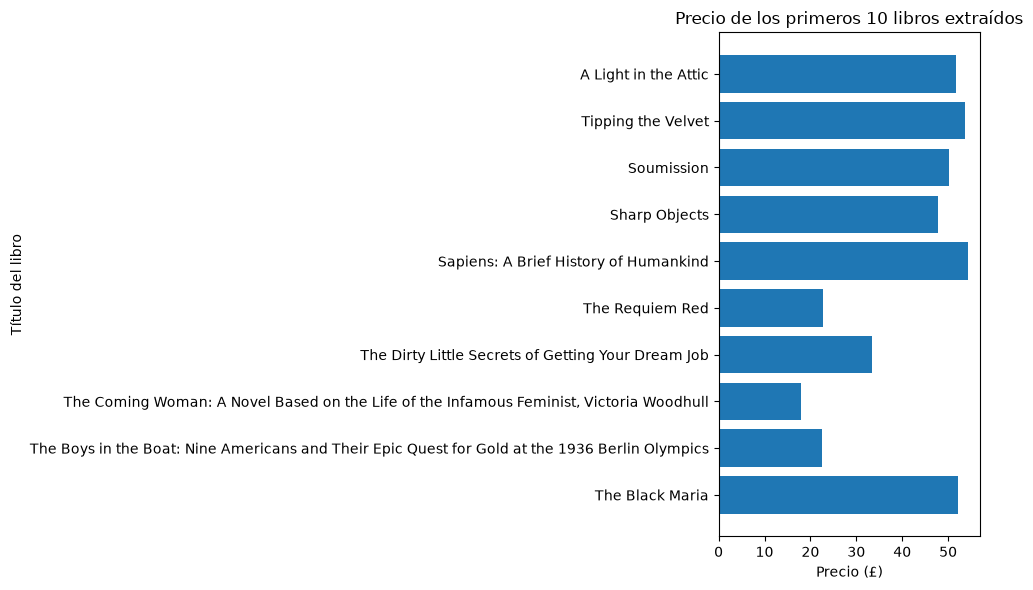

In [10]:
import matplotlib.pyplot as plt

top10 = df.head(10)

plt.figure(figsize=(10, 6))
plt.barh(top10["Titulo"], top10["Precio_GBP"])
plt.xlabel("Precio (£)")
plt.ylabel("Título del libro")
plt.title("Precio de los primeros 10 libros extraídos")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("grafica_precios_libros.png", dpi=300, bbox_inches="tight")
plt.show()

In [11]:
resumen = pd.DataFrame({
    "Indicador": [
        "Total de libros",
        "Precio promedio (£)",
        "Precio mínimo (£)",
        "Precio máximo (£)",
        "Registros completos",
        "Completitud (%)"
    ],
    "Resultado": [
        len(df),
        round(df["Precio_GBP"].mean(), 2),
        round(df["Precio_GBP"].min(), 2),
        round(df["Precio_GBP"].max(), 2),
        df.dropna(subset=["Titulo", "Precio_GBP"]).shape[0],
        round(df.dropna(subset=["Titulo", "Precio_GBP"]).shape[0] / len(df) * 100, 2)
    ]
})

display(resumen)

resumen.to_csv("resumen_analisis.csv", index=False, encoding="utf-8-sig")

print("Resumen guardado correctamente.")

,Indicador,Resultado
0,Total de libros,20.00
1,Precio promedio (£),38.05
2,Precio mínimo (£),13.99
3,Precio máximo (£),57.25
4,Registros completos,20.00
5,Completitud (%),100.00


Resumen guardado correctamente.


## 3. Resultados y análisis

Durante la práctica se realizó una extracción de información de la página Books to Scrape mediante Python, Requests y BeautifulSoup. Se obtuvieron 20 registros correspondientes a los libros publicados en la primera página consultada.

El análisis mostró un precio promedio de £38,05, un precio mínimo de £13,99 y un precio máximo de £57,25. Estos resultados evidencian que existe una diferencia considerable entre los precios de los productos analizados.

En la validación se identificaron 20 registros completos, sin títulos ni precios vacíos y sin títulos duplicados. La completitud de los campos evaluados fue del 100 %. Este indicador se refiere únicamente a los títulos y precios de los registros extraídos, no a la totalidad de la información disponible en la tienda.

La gráfica de barras permitió comparar visualmente los precios de los primeros diez libros y reconocer sus diferencias. Además, los resultados se exportaron a archivos CSV para facilitar su consulta y reutilización en otros ejercicios de análisis de datos.

## 4. Conclusiones

La práctica permitió comprender cómo funciona el web scraping y cómo puede utilizarse para recopilar información publicada en una página web. La combinación de Requests y BeautifulSoup resultó adecuada para este ejercicio porque los datos de los productos estaban disponibles en el HTML recibido.

También se comprobó que la extracción automatizada debe complementarse con procesos de validación, transformación y análisis. Obtener información no es suficiente: es necesario revisar su integridad, convertir los valores a un formato adecuado y presentar los resultados de manera comprensible.

Finalmente, la experiencia permitió reconocer las diferencias entre BeautifulSoup, Selenium y Scrapy. Cada herramienta responde a necesidades particulares y su elección depende de la estructura del sitio, la complejidad del proceso y el volumen de información requerido. Como trabajo futuro, se podría ampliar el análisis a más páginas y estudiar otras variables comerciales.

## 5. Planteamiento del problema

Las tiendas de comercio electrónico publican información sobre sus productos que puede ser útil para estudiar precios, disponibilidad y características de la oferta comercial. Sin embargo, cuando se necesita recopilar información de varios productos, hacerlo manualmente puede consumir tiempo y dificultar la organización de los datos.

Ante esta situación, surge la siguiente pregunta de investigación:

¿Cómo se puede utilizar el web scraping para recopilar, organizar y analizar información de productos publicados en una tienda en línea?

Para abordar esta pregunta, se seleccionó Books to Scrape, una tienda de demostración diseñada para practicar la extracción de información web. Se eligió esta fuente porque permite acceder a datos de productos en un entorno apropiado para el aprendizaje.

La práctica se desarrolló con Python, Requests y BeautifulSoup. Se extrajeron títulos y precios, se organizaron los resultados en una tabla, se calcularon estadísticas descriptivas y se verificó la integridad de los datos obtenidos.

También se revisaron Selenium y Scrapy para comprender sus diferencias y reconocer en qué situaciones podrían resultar más adecuados. La comparación permite relacionar la selección de una herramienta con las características técnicas de la página y las necesidades del análisis.

## 6. Objetivos

### Objetivo general

Aplicar la metodología de web scraping mediante Python para extraer, organizar y analizar información de productos publicados en una tienda de comercio electrónico, evaluando la utilidad de los datos obtenidos para el análisis comercial.

### Objetivos específicos

1. Identificar las características de Books to Scrape y seleccionar la información de los productos que se analizará durante la práctica.

2. Implementar una solución de extracción de datos utilizando Requests y BeautifulSoup para recopilar los títulos y precios de los libros publicados en la primera página.

3. Organizar la información obtenida mediante pandas y exportarla a archivos CSV para facilitar su almacenamiento y posterior análisis.

4. Calcular indicadores descriptivos, como el precio promedio, el mínimo y el máximo, y representar visualmente los precios mediante una gráfica.

5. Validar la calidad de los datos extraídos y comparar las características de BeautifulSoup, Selenium y Scrapy para reconocer sus posibles aplicaciones.

### Justificación del análisis

El análisis de los libros se realiza para comprender cómo la extracción automatizada facilita la recopilación y organización de información comercial. Aunque los precios no permiten determinar por sí solos la calidad o la demanda de un producto, sí ofrecen una base para describir la oferta disponible y practicar técnicas de análisis de datos.

## 7. Metodología empleada

La práctica se desarrolló mediante una metodología aplicada, con un enfoque cuantitativo descriptivo, porque se recopilaron datos numéricos y textuales de una página web para organizarlos y analizarlos.

### 7.1. Selección de la fuente

Se seleccionó Books to Scrape (https://books.toscrape.com/), una tienda de demostración diseñada para practicar técnicas de extracción de información web. Se trabajó con los productos de la primera página consultada, sin realizar compras ni modificar información del sitio.

### 7.2. Herramientas utilizadas

- Python:lenguaje de programación empleado para desarrollar el procedimiento.
- Requests:biblioteca utilizada para solicitar el contenido HTML de la página.
- BeautifulSoup:herramienta empleada para analizar el HTML e identificar los elementos que contienen los títulos y precios.
- pandas:biblioteca utilizada para organizar los registros en una tabla y exportarlos a archivos CSV.
- Matplotlib:herramienta utilizada para representar gráficamente los precios.

Selenium y Scrapy se estudiaron como alternativas metodológicas, pero no se implementaron en esta ejecución.

### 7.3. Procedimiento de extracción

Primero, se realizó una solicitud HTTP a la página principal mediante Requests. Después, se verificó el código de respuesta para comprobar que el contenido se recibiera correctamente.

Posteriormente, BeautifulSoup interpretó el HTML recibido y permitió localizar los elementos correspondientes a los productos. De cada libro se extrajeron el título y el precio publicado. Los registros se organizaron en una estructura de datos y se transformaron en un DataFrame de pandas.

A continuación, los precios se convirtieron a valores numéricos para facilitar los cálculos. Se obtuvieron el promedio, el valor mínimo y el máximo. Finalmente, se validaron los datos, se generó una gráfica de barras y se exportaron los resultados a archivos CSV.

### 7.4. Métricas de éxito

Se establecieron los siguientes indicadores para evaluar la ejecución:

1. Cantidad de registros extraídos:verificar que se obtuvieran los 20 libros de la primera página.
2. Completitud:calcular el porcentaje de registros que tienen título y precio.
3. Datos faltantes:identificar títulos o precios vacíos.
4. Duplicados:comprobar si existen títulos repetidos.
5. Procesamiento numérico:verificar que los precios se puedan utilizar en cálculos estadísticos.
6. Exportación:confirmar la creación de los archivos CSV y de la gráfica de precios.

### 7.5. Alcance y limitaciones

Los resultados corresponden únicamente a los productos encontrados en la primera página consultada y no representan toda la tienda. Los precios están expresados en libras esterlinas, de acuerdo con los datos publicados por el sitio. La extracción se limita a los títulos y precios, por lo que no permite concluir cuál libro tiene mayor demanda ni evaluar la satisfacción de los compradores.

La práctica demuestra el funcionamiento básico de Requests y BeautifulSoup en una página de demostración. La aplicación a otros sitios dependerá de su estructura HTML, sus condiciones de acceso y las medidas técnicas que utilicen.


## 8. Comparación de las herramientas de Web Scraping

Aunque BeautifulSoup, Selenium y Scrapy permiten trabajar con información de páginas web, sus funciones y características son diferentes.

### BeautifulSoup

BeautifulSoup es una biblioteca de Python que permite analizar documentos HTML y XML para localizar elementos específicos. En esta práctica se utilizó para identificar los títulos y precios de los libros mediante selectores CSS.

Su principal ventaja es la facilidad de uso cuando el contenido necesario ya está presente en el HTML recibido. Por sí sola, no realiza las solicitudes web, por lo que en este ejercicio se complementó con Requests.

### Selenium

Selenium permite automatizar navegadores web y realizar acciones como hacer clic, completar formularios, desplazarse por una página y esperar a que aparezca contenido dinámico.

Podría resultar útil si una tienda requiere interacciones con el navegador para mostrar determinada información. Sin embargo, su configuración y ejecución pueden requerir más recursos que una solicitud HTTP sencilla.

### Scrapy

Scrapy es un framework de Python diseñado para desarrollar proyectos de rastreo y extracción web más estructurados. Permite definir reglas de seguimiento entre páginas, procesar grandes cantidades de registros y exportar resultados.

Sería una alternativa apropiada para ampliar esta práctica a varias páginas de productos, establecer reglas de navegación y administrar procesos de extracción más complejos.

### Justificación de la elección

Para esta primera práctica se eligió Requests junto con BeautifulSoup, porque los títulos y precios estaban disponibles directamente en el HTML de la página consultada. Esta solución permitió obtener los datos con un procedimiento sencillo, comprobar su integridad y organizarlos para el análisis estadístico.

Selenium y Scrapy se presentan como alternativas técnicas, pero no se afirma que hayan sido ejecutados durante esta práctica. La selección de una herramienta depende de la estructura del sitio web, la forma en que se carga la información, el volumen de datos y las condiciones de acceso.


## 9. Referencias bibliográficas

Beautiful Soup. (s. f.). *Beautiful Soup documentation*. https://beautiful-soup-4.readthedocs.io/en/latest/

Matplotlib Development Team. (s. f.). *Matplotlib documentation*. https://matplotlib.org/stable/

Pandas Development Team. (s. f.). *pandas documentation*. https://pandas.pydata.org/docs/

Python Software Foundation. (s. f.). *Python documentation*. https://docs.python.org/3/

Requests. (s. f.). *Requests: HTTP for humans*. https://requests.readthedocs.io/en/latest/

Scrapy. (s. f.). *Scrapy documentation*. https://docs.scrapy.org/en/latest/

Selenium. (s. f.). *Selenium documentation*. https://www.selenium.dev/documentation/

ToScrape. (s. f.). *Books to Scrape*. https://books.toscrape.com/
